# MODELISATION PREDICTIVE DES SINISTRES AUTO

# 1/ Présentation du projet

# Introduction

ce projet vise à prédire le coût des sinistres automobiles en utilisant différents modèles statistiques et de machine learning.  
Objectif : comparer Tweedie et LightGBM, analyser leurs limites, puis construire un pipeline robuste.

In [87]:
import os
import sklearn

In [202]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import TweedieRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_tweedie_deviance
import lightgbm as lgb
from sklearn.metrics import r2_score
from sklearn.linear_model import GammaRegressor
from sklearn.linear_model import LogisticRegression


%matplotlib inline pour afficher le graphique directement aprés le code 

# 2/ Importation des données

In [89]:
claimsauto = pd.read_excel("C:/Users/Admin/Desktop/PROJET 2026/Carclaimsforinsurance.xlsx")

In [90]:
claimsauto.head()

,ID,KIDSDRIV,BIRTH,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,...,OCCUPATION,TRAVTIME,CAR_USE,BLUEBOOK,CAR_TYPE,OLDCLAIM,CLM_FREQ,CLM_AMT,CAR_AGE,URBANICITY
0,100130023,0,1955-02-05,2,13,26763,Yes,141019,No,F,...,Manager,49,Private,11500,SUV,0,0,0,11,Highly Urban/ Urban
1,100263241,0,1961-10-05,0,9,156060,No,381438,Yes,M,...,Blue Collar,29,Commercial,25230,Panel Truck,8207,1,0,9,Highly Urban/ Urban
2,100321982,0,1959-11-12,1,11,1965,Yes,0,No,F,...,Home Maker,21,Private,20630,Minivan,0,0,0,11,Highly Urban/ Urban
3,100391818,0,1961-10-11,1,10,62361,No,185738,Yes,F,...,Home Maker,32,Private,11540,SUV,3481,1,0,6,Highly Urban/ Urban
4,100549277,0,1966-10-06,1,10,34192,Yes,0,No,F,...,Blue Collar,22,Commercial,13670,SUV,0,0,0,7,Highly Rural/ Rural


In [91]:
claimsauto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7647 entries, 0 to 7646
Data columns (total 21 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   ID          7647 non-null   int64         
 1   KIDSDRIV    7647 non-null   int64         
 2   BIRTH       7647 non-null   datetime64[ns]
 3   HOMEKIDS    7647 non-null   int64         
 4   YOJ         7647 non-null   int64         
 5   INCOME      7647 non-null   int64         
 6   PARENT1     7647 non-null   object        
 7   HOME_VAL    7647 non-null   int64         
 8   MSTATUS     7647 non-null   object        
 9   GENDER      7647 non-null   object        
 10  EDUCATION   7647 non-null   object        
 11  OCCUPATION  7647 non-null   object        
 12  TRAVTIME    7647 non-null   int64         
 13  CAR_USE     7647 non-null   object        
 14  BLUEBOOK    7647 non-null   int64         
 15  CAR_TYPE    7647 non-null   object        
 16  OLDCLAIM    7647 non-nul

In [92]:
claimsauto.describe()

,ID,KIDSDRIV,HOMEKIDS,YOJ,INCOME,HOME_VAL,TRAVTIME,BLUEBOOK,OLDCLAIM,CLM_FREQ,CLM_AMT,CAR_AGE
count,7.647000e+03,7647.000000,7647.000000,7647.000000,7647.000000,7647.000000,7647.000000,7647.000000,7647.000000,7647.000000,7647.000000,7647.000000
mean,5.526776e+08,0.171701,0.741206,10.440173,57827.276318,149934.203478,33.662220,15176.001046,4028.652282,0.789591,1482.270694,7.888715
std,2.598341e+08,0.509594,1.129170,4.166907,43979.819478,124097.647931,15.858708,8077.185973,8809.719523,1.151058,4433.849079,5.586481
min,1.001300e+08,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,1500.000000,0.000000,0.000000,0.000000,-3.000000
25%,3.290372e+08,0.000000,0.000000,9.000000,26125.000000,0.000000,23.000000,9030.000000,0.000000,0.000000,0.000000,1.000000
50%,5.503528e+08,0.000000,0.000000,11.000000,51121.000000,158688.000000,33.000000,14020.000000,0.000000,0.000000,0.000000,8.000000
75%,7.792809e+08,0.000000,1.000000,13.000000,81002.500000,232840.500000,44.000000,20085.000000,4600.000000,2.000000,1165.500000,12.000000
max,9.997993e+08,4.000000,5.000000,19.000000,367030.000000,885282.000000,142.000000,65970.000000,57037.000000,5.000000,85524.000000,28.000000


In [93]:
claimsauto.columns

Index(['ID', 'KIDSDRIV', 'BIRTH', 'HOMEKIDS', 'YOJ', 'INCOME', 'PARENT1',
       'HOME_VAL', 'MSTATUS', 'GENDER', 'EDUCATION', 'OCCUPATION', 'TRAVTIME',
       'CAR_USE', 'BLUEBOOK', 'CAR_TYPE', 'OLDCLAIM', 'CLM_FREQ', 'CLM_AMT',
       'CAR_AGE', 'URBANICITY'],
      dtype='object')

# 3/ Nettoyage et préparation des données

In [94]:
claimsauto.isnull().sum()

ID            0
KIDSDRIV      0
BIRTH         0
HOMEKIDS      0
YOJ           0
INCOME        0
PARENT1       0
HOME_VAL      0
MSTATUS       0
GENDER        0
EDUCATION     0
OCCUPATION    0
TRAVTIME      0
CAR_USE       0
BLUEBOOK      0
CAR_TYPE      0
OLDCLAIM      0
CLM_FREQ      0
CLM_AMT       0
CAR_AGE       0
URBANICITY    0
dtype: int64

In [95]:
categorical_cols=claimsauto.select_dtypes(include=['object','category']).columns

In [96]:
print(categorical_cols)

Index(['PARENT1', 'MSTATUS', 'GENDER', 'EDUCATION', 'OCCUPATION', 'CAR_USE',
       'CAR_TYPE', 'URBANICITY'],
      dtype='object')


In [97]:
claimsauto["CAR_USE"].unique()

array(['Private', 'Commercial'], dtype=object)

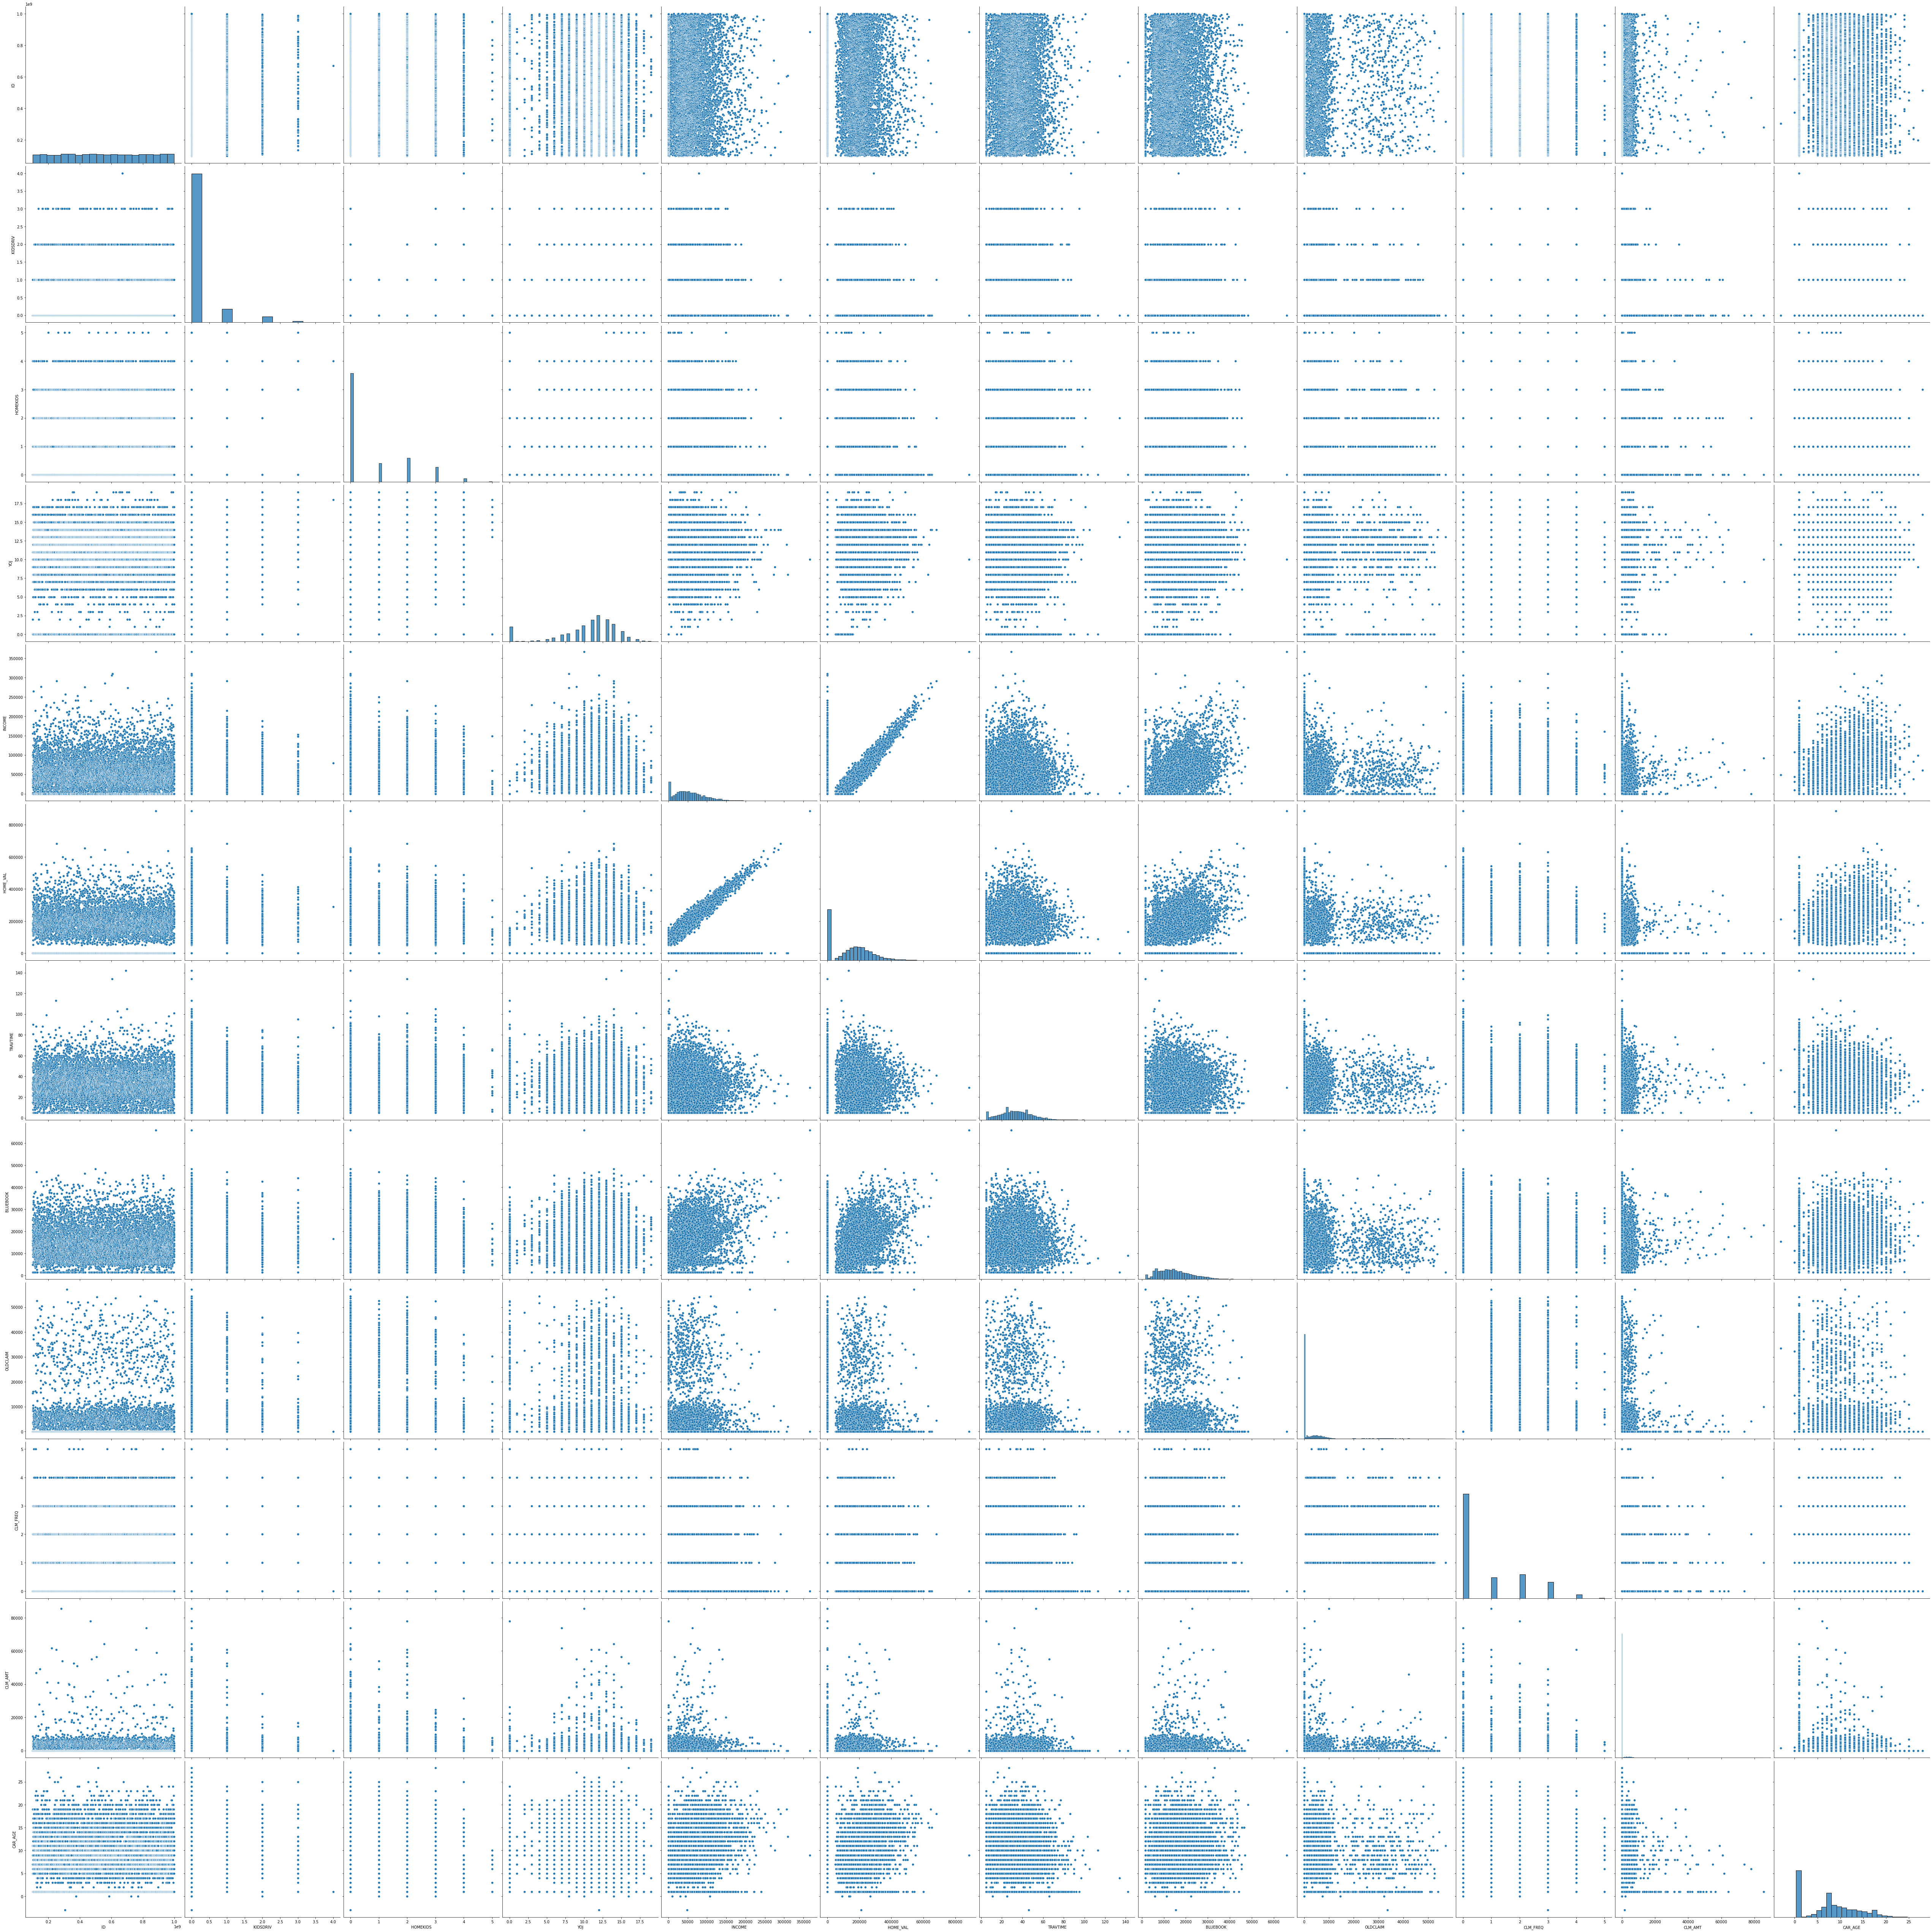

In [98]:
sns.pairplot(claimsauto, height=6)
plt.show()

In [99]:
# Analuse de la varibale "CLM_FREQ"

C:\Users\Admin\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='CLM_FREQ', ylabel='Density'>

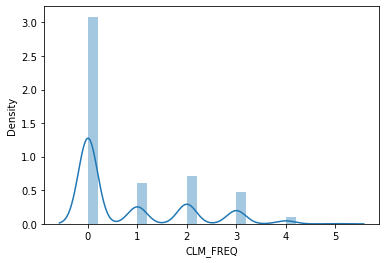

In [100]:
sns.distplot(claimsauto['CLM_FREQ'])

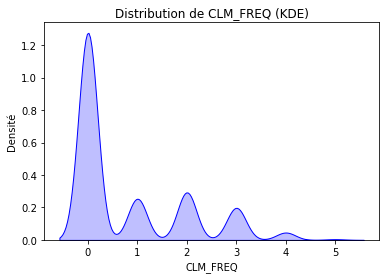

In [101]:
sns.kdeplot(data=claimsauto, x="CLM_FREQ", fill=True, color="blue")

plt.title("Distribution de CLM_FREQ (KDE)")
plt.xlabel("CLM_FREQ")

plt.ylabel("Densité")
plt.show()

je vais supprimer la variable Fréquence "CLM_FREQ" car Le Tweedie est utilisé pour modéliser le coût total des sinistres (claim cost). Ce coût est en fait la combinaison de deux composantes :fréquence et severité et la gardant on risque de douber l'information



In [102]:
claimsauto=claimsauto.drop(["CLM_FREQ"], axis=1)

la densité des nombre 0 est grande vaut dire que beaucoup de clients n'ont pas de sinistres et les autres ont trés peu de sinistres 

C:\Users\Admin\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='CLM_AMT', ylabel='Density'>

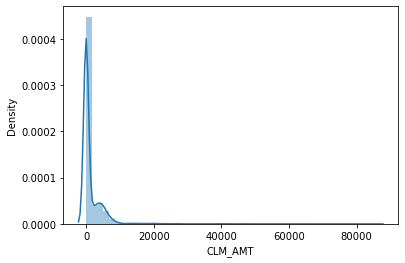

In [103]:
sns.distplot(claimsauto['CLM_AMT'])

ce graphe montre que l plupart des client ont un cout de sinistre trés faible ou null et le reste c'est une queue à droite longue 
ces deux graphes montrent que notre base de données est adaptée pour un modèle tweedie 

<AxesSubplot:>

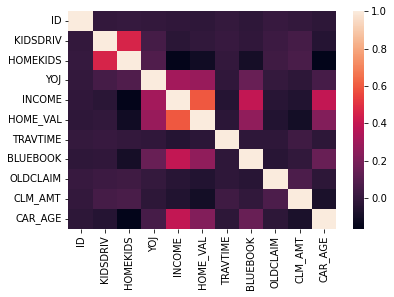

In [104]:
sns.heatmap(claimsauto.corr())

# Encodage des variables catégorielles

avant de passer à tweedie il faut encoder les variables catégorielles



pour les variables dont les valeurs sont yes or No 'PARENT1' et 'MSTATUS' les encoder manuellement

pour la variable "BIRTH" qui est une date on extrait l'année, le mois et le jour en créant ces trois variables "year", "month" et "day"

In [105]:
claimsauto["MSTATUS"]=claimsauto["MSTATUS"].map({"Yes":1,"No":0})

In [106]:
claimsauto["PARENT1"]=claimsauto["PARENT1"].map({"Yes":1,"No":0})

In [107]:
claimsauto["GENDER"]=claimsauto["GENDER"].map({"M":1,"F":0})

In [108]:
claimsauto["BIRTH"]

0      1955-02-05
1      1961-10-05
2      1959-11-12
3      1961-10-11
4      1966-10-06
          ...    
7642   1938-08-28
7643   1968-12-24
7644   1957-03-27
7645   1951-06-09
7646   1952-07-21
Name: BIRTH, Length: 7647, dtype: datetime64[ns]

In [109]:
claimsauto["year"]= claimsauto["BIRTH"].dt.year

In [110]:
claimsauto["month"]= claimsauto["BIRTH"].dt.month

In [111]:
claimsauto["day"]= claimsauto["BIRTH"].dt.day

In [112]:
claimsauto.columns

Index(['ID', 'KIDSDRIV', 'BIRTH', 'HOMEKIDS', 'YOJ', 'INCOME', 'PARENT1',
       'HOME_VAL', 'MSTATUS', 'GENDER', 'EDUCATION', 'OCCUPATION', 'TRAVTIME',
       'CAR_USE', 'BLUEBOOK', 'CAR_TYPE', 'OLDCLAIM', 'CLM_AMT', 'CAR_AGE',
       'URBANICITY', 'year', 'month', 'day'],
      dtype='object')

In [113]:
claimsauto["EDUCATION"]

0           Masters
1         Bachelors
2               PhD
3         Bachelors
4       High School
           ...     
7642      Bachelors
7643    High School
7644      Bachelors
7645    High School
7646        Masters
Name: EDUCATION, Length: 7647, dtype: object

In [114]:
claimsauto["CAR_TYPE"]

0               SUV
1       Panel Truck
2           Minivan
3               SUV
4               SUV
           ...     
7642     Sports Car
7643         Pickup
7644        Minivan
7645        Minivan
7646            SUV
Name: CAR_TYPE, Length: 7647, dtype: object

pour la variable "EDUCATION" on utilise "LabelEncoder" qui donne une valeur à chaque niveau d'éducation

In [115]:
claimsauto["CAR_USE"]

0          Private
1       Commercial
2          Private
3          Private
4       Commercial
           ...    
7642       Private
7643    Commercial
7644       Private
7645    Commercial
7646       Private
Name: CAR_USE, Length: 7647, dtype: object

In [116]:
le=LabelEncoder()

In [117]:
claimsauto["EDUCATION-encoded"]= le.fit_transform(claimsauto["EDUCATION"])

In [118]:
claimsauto["CAR_TYPE-encoded"]= le.fit_transform(claimsauto["CAR_TYPE"])

In [119]:
claimsauto["CAR_USE-encoded"]= le.fit_transform(claimsauto["CAR_USE"])

In [120]:
claimsauto_encoded=pd.get_dummies(claimsauto, columns=["OCCUPATION"],drop_first=False)

j'avais utilisé label encoder mais ça m'a donné des résultats pas trés cohérents car il suppose un ordre entre les différents types d'occupation et j'ai trouvé le coéfficient =1.707484 et son Exp=5.515070 cela signifie que le premier type ou le type de référence influent *5 le résultat du cout de sinistre, et le second type va influer deux fois plus le résultat ce qui n'est pas logique pour cette variable


je veux voir les valeurs uniques des variables que je veux encoder

In [121]:
claimsauto["OCCUPATION"].unique()

array(['Manager', 'Blue Collar', 'Home Maker', 'Clerical', 'Lawyer',
       'Student', 'Professional', 'Doctor'], dtype=object)

In [122]:
claimsauto_encoded

,ID,KIDSDRIV,BIRTH,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,...,CAR_TYPE-encoded,CAR_USE-encoded,OCCUPATION_Blue Collar,OCCUPATION_Clerical,OCCUPATION_Doctor,OCCUPATION_Home Maker,OCCUPATION_Lawyer,OCCUPATION_Manager,OCCUPATION_Professional,OCCUPATION_Student
0,100130023,0,1955-02-05,2,13,26763,1,141019,0,0,...,3,1,0,0,0,0,0,1,0,0
1,100263241,0,1961-10-05,0,9,156060,0,381438,1,1,...,1,0,1,0,0,0,0,0,0,0
2,100321982,0,1959-11-12,1,11,1965,1,0,0,0,...,0,1,0,0,0,1,0,0,0,0
3,100391818,0,1961-10-11,1,10,62361,0,185738,1,0,...,3,1,0,0,0,1,0,0,0,0
4,100549277,0,1966-10-06,1,10,34192,1,0,0,0,...,3,0,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7642,999532945,0,1938-08-28,0,11,67813,0,249997,1,0,...,4,1,0,0,0,0,0,0,1,0
7643,999575184,0,1968-12-24,2,11,13490,0,95447,1,1,...,2,0,0,0,0,0,0,0,0,1
7644,999612102,0,1957-03-27,1,11,44955,0,161808,1,1,...,0,1,0,0,0,0,0,0,1,0
7645,999756883,0,1951-06-09,0,13,36835,0,167142,1,1,...,0,0,1,0,0,0,0,0,0,0


In [123]:
claimsauto["EDUCATION-encoded"].unique()

array([3, 1, 4, 2, 0])

In [124]:
claimsauto["CAR_TYPE-encoded"].unique()

array([3, 1, 0, 2, 5, 4])

In [125]:
claimsauto["CAR_USE-encoded"].unique()

array([1, 0])

In [126]:
claimsauto["CAR_USE"].unique()

array(['Private', 'Commercial'], dtype=object)

In [127]:
claimsauto["CAR_TYPE"].unique()

array(['SUV', 'Panel Truck', 'Minivan', 'Pickup', 'Van', 'Sports Car'],
      dtype=object)

In [128]:
claimsauto_encoded = pd.get_dummies(claimsauto_encoded, columns=["URBANICITY"], drop_first=True)

# là on a encodé la variable URBANICITY avec one hote encoded 




In [129]:
claimsauto_encoded

,ID,KIDSDRIV,BIRTH,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,...,CAR_USE-encoded,OCCUPATION_Blue Collar,OCCUPATION_Clerical,OCCUPATION_Doctor,OCCUPATION_Home Maker,OCCUPATION_Lawyer,OCCUPATION_Manager,OCCUPATION_Professional,OCCUPATION_Student,URBANICITY_Highly Urban/ Urban
0,100130023,0,1955-02-05,2,13,26763,1,141019,0,0,...,1,0,0,0,0,0,1,0,0,1
1,100263241,0,1961-10-05,0,9,156060,0,381438,1,1,...,0,1,0,0,0,0,0,0,0,1
2,100321982,0,1959-11-12,1,11,1965,1,0,0,0,...,1,0,0,0,1,0,0,0,0,1
3,100391818,0,1961-10-11,1,10,62361,0,185738,1,0,...,1,0,0,0,1,0,0,0,0,1
4,100549277,0,1966-10-06,1,10,34192,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7642,999532945,0,1938-08-28,0,11,67813,0,249997,1,0,...,1,0,0,0,0,0,0,1,0,0
7643,999575184,0,1968-12-24,2,11,13490,0,95447,1,1,...,0,0,0,0,0,0,0,0,1,1
7644,999612102,0,1957-03-27,1,11,44955,0,161808,1,1,...,1,0,0,0,0,0,0,1,0,1
7645,999756883,0,1951-06-09,0,13,36835,0,167142,1,1,...,0,1,0,0,0,0,0,0,0,1


In [130]:
claimsauto_encoded["MSTATUS"].unique()

array([0, 1], dtype=int64)

il nous reste le colonne "BIRTH" qui est en date on doit la supprimer car on la sectioné en "year", "month" et "day" car on ne peut pas entrainer le modèle tweedie avec une variable catégorielle

# maintenant on supprime la colonne "BIRTH" qui est une date avat de passer à la méthode TWEEDIE ainsi que les variables qui ont fait l'objet d'encodage

In [131]:
claimsauto_encoded=claimsauto_encoded.drop ("BIRTH", axis=1)

In [132]:
claimsauto_encoded=claimsauto_encoded.drop(columns=["ID"])
claimsauto_encoded=claimsauto_encoded.drop(columns=["day"],errors="ignore")

In [133]:
claimsauto_encoded=claimsauto_encoded.drop(columns=["CAR_USE"])

In [134]:
claimsauto_encoded=claimsauto_encoded.drop(columns=["CAR_TYPE"])

In [135]:
claimsauto_encoded.columns

Index(['KIDSDRIV', 'HOMEKIDS', 'YOJ', 'INCOME', 'PARENT1', 'HOME_VAL',
       'MSTATUS', 'GENDER', 'EDUCATION', 'TRAVTIME', 'BLUEBOOK', 'OLDCLAIM',
       'CLM_AMT', 'CAR_AGE', 'year', 'month', 'EDUCATION-encoded',
       'CAR_TYPE-encoded', 'CAR_USE-encoded', 'OCCUPATION_Blue Collar',
       'OCCUPATION_Clerical', 'OCCUPATION_Doctor', 'OCCUPATION_Home Maker',
       'OCCUPATION_Lawyer', 'OCCUPATION_Manager', 'OCCUPATION_Professional',
       'OCCUPATION_Student', 'URBANICITY_Highly Urban/ Urban'],
      dtype='object')

# MAINTENANT ON PEUT PASSER A LA METHODE TWEEDIE et choisir les parametres

pourquoi tweedie parsqu'elle permet de modéliser des montants avec beaucoup de zéros et des valeurs positifs

avec P entre 0 et 1 dans notre cas P= 1,5

séparer les colonnes explicatives "x" et les colonnes cible "y" qui est "CLM_AMT"

In [136]:
x= claimsauto_encoded.drop (columns=["CLM_AMT"], axis=1)

In [137]:
y= claimsauto_encoded["CLM_AMT"]

C:\Users\Admin\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='CLM_AMT', ylabel='Density'>

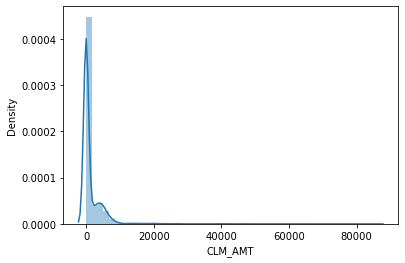

In [138]:
sns.distplot(claimsauto['CLM_AMT'])

# 4/ MODELISATION TWEEDIE

## 4-1 Application du modèle TWEEDIE ##

séparer les données test et les données train

In [139]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=100)

In [140]:
continuous_vars = [
    col for col in x_train.select_dtypes(include=["int64","float64"]).columns
    if x_train[col].nunique() > 2
]

## 4-2 Normalisation des variables continues ##

In [141]:
scaler = StandardScaler()
x_train[continuous_vars] = scaler.fit_transform(x_train[continuous_vars])
x_test[continuous_vars] = scaler.transform(x_test[continuous_vars])

In [142]:
model_tweedie=TweedieRegressor(power=1.5,alpha=10,link="log", max_iter=10000)

In [143]:
claimsauto_encoded.columns

Index(['KIDSDRIV', 'HOMEKIDS', 'YOJ', 'INCOME', 'PARENT1', 'HOME_VAL',
       'MSTATUS', 'GENDER', 'EDUCATION', 'TRAVTIME', 'BLUEBOOK', 'OLDCLAIM',
       'CLM_AMT', 'CAR_AGE', 'year', 'month', 'EDUCATION-encoded',
       'CAR_TYPE-encoded', 'CAR_USE-encoded', 'OCCUPATION_Blue Collar',
       'OCCUPATION_Clerical', 'OCCUPATION_Doctor', 'OCCUPATION_Home Maker',
       'OCCUPATION_Lawyer', 'OCCUPATION_Manager', 'OCCUPATION_Professional',
       'OCCUPATION_Student', 'URBANICITY_Highly Urban/ Urban'],
      dtype='object')

In [144]:
claimsauto_encoded["CLM_AMT"]

0          0
1          0
2          0
3          0
4          0
        ... 
7642       0
7643    4578
7644    3128
7645       0
7646       0
Name: CLM_AMT, Length: 7647, dtype: int64

#on passe à l'entrainement du modèle

In [145]:
model_tweedie.fit(x_train,y_train)

ValueError: could not convert string to float: 'Masters'

#apparement j'ai des variables textes je fais ça pour voir lesquelles 


In [146]:
non_numeric = x_train.select_dtypes(include=['object']).columns
print(non_numeric)

Index(['EDUCATION'], dtype='object')


#i
l faut les supprimer et garder les meme encodées

In [147]:
claimsauto_encoded=claimsauto_encoded.drop(columns=["EDUCATION"],axis=1)


In [148]:
claimsauto_encoded

,KIDSDRIV,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,TRAVTIME,BLUEBOOK,...,CAR_USE-encoded,OCCUPATION_Blue Collar,OCCUPATION_Clerical,OCCUPATION_Doctor,OCCUPATION_Home Maker,OCCUPATION_Lawyer,OCCUPATION_Manager,OCCUPATION_Professional,OCCUPATION_Student,URBANICITY_Highly Urban/ Urban
0,0,2,13,26763,1,141019,0,0,49,11500,...,1,0,0,0,0,0,1,0,0,1
1,0,0,9,156060,0,381438,1,1,29,25230,...,0,1,0,0,0,0,0,0,0,1
2,0,1,11,1965,1,0,0,0,21,20630,...,1,0,0,0,1,0,0,0,0,1
3,0,1,10,62361,0,185738,1,0,32,11540,...,1,0,0,0,1,0,0,0,0,1
4,0,1,10,34192,1,0,0,0,22,13670,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7642,0,0,11,67813,0,249997,1,0,51,21190,...,1,0,0,0,0,0,0,1,0,0
7643,0,2,11,13490,0,95447,1,1,5,5850,...,0,0,0,0,0,0,0,0,1,1
7644,0,1,11,44955,0,161808,1,1,30,18790,...,1,0,0,0,0,0,0,1,0,1
7645,0,0,13,36835,0,167142,1,1,20,17360,...,0,1,0,0,0,0,0,0,0,1



# maintenant on refait l'entrainement du modèle

In [149]:
x= claimsauto_encoded.drop (columns=["CLM_AMT"], axis=1)

In [150]:
y= claimsauto_encoded["CLM_AMT"]

In [151]:
y=y+1e-6

In [152]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [153]:
continuous_vars = [columns for columns in x_train.columns if x_train[columns].nunique() > 4] 

In [154]:
scaler = StandardScaler()
x_train[continuous_vars] = scaler.fit_transform(x_train[continuous_vars])
x_test[continuous_vars] = scaler.transform(x_test[continuous_vars])

In [155]:
model_tweedie.fit(x_train,y_train)

TweedieRegressor(alpha=10, link='log', max_iter=10000, power=1.5)

## Calcul des coefficients du modèle Tweedie ##

avant d'extraire les coefficients du modèle je dois vérifier que le nombre de colonnes est de la meme taille que "model.coef"


In [156]:
print(len(claimsauto_encoded.columns))

27


In [157]:
print(type (model_tweedie))

<class 'sklearn.linear_model._glm.glm.TweedieRegressor'>


In [158]:
print(len(model_tweedie.coef_))

26


In [159]:
import sklearn
print(sklearn.__version__)

1.4.2


In [160]:
type(model_tweedie)

sklearn.linear_model._glm.glm.TweedieRegressor

In [161]:
print(model_tweedie.coef_)

[ 0.10290509  0.04971839  0.02551477 -0.08807643  0.13202471 -0.15867572
 -0.18929641  0.02439506  0.11751863  0.04743577  0.13165149 -0.12681746
  0.0550166   0.00277018 -0.03131482  0.1870812  -0.2316391   0.13791134
 -0.00380918 -0.03795744 -0.01506008  0.01434299 -0.147717    0.0831072
 -0.03082451  0.43908044]


In [162]:
intercept = model_tweedie.intercept_
print(intercept)

6.970391779526182


# là on voit que le nbre de colonnes est 27 et la taille du modèle est 26

ça vient du fait que le l'intercept est socké séparément il n'est pas dans model.coeff donc c'est le coefficient qui manque 


on va l'ajouter 

intercept_df = pd.DataFrame({
    'variable': ['Intercept'],
    'coefficient': [model.intercept_[0]],
    'exp(coefficient)': [np.exp(model.intercept_[0])]

In [163]:
result= pd.DataFrame({
    'variable':x_train.columns,
    'coefficient':model_tweedie.coef_,
    'exp(coefficient)':np.exp(model_tweedie.coef_)
})

# la preuve là on a une erreur car on l'a pas encore ajouté 

intercept_df = pd.DataFrame({
    'variable': ['Intercept'],
    'coefficient': [model.intercept_[0]],
    'exp(coefficient)': [np.exp(model.intercept_[0])]

In [164]:
result= pd.DataFrame({
    'variable':claimsauto_encoded.columns,
    'coefficient':model_tweedie.coef_.ravel(),
    'exp(coefficient)':np.exp(model_tweedie.coef_.ravel())
})

intercept_df = pd.DataFrame({
    'variable':['Intercept'],
    'coefficient':[model_tweedie.intercept_],
    'exp(coefficient)':[np.exp(model_tweedie.intercept_)]
})

result=pd.concat([intercept_df,result], ignore_index=True)

ValueError: All arrays must be of the same length

# on a toujours le meme pb car il faut ajuster le nombre de colonnes au model.coeff 
on fait

'variable':claimsauto_encoded.columns[:len(model.coef_]

In [ ]:
result= pd.DataFrame({
    'variable':claimsauto_encoded.columns[:len(model_tweedie.coef_)],
    'coefficient':model_tweedie.coef_.ravel(),
    'exp(coefficient)':np.exp(model_tweedie.coef_.ravel())
})

intercept_df = pd.DataFrame({
    'variable':['Intercept'],
    'coefficient':[model_tweedie.intercept_],
    'exp(coefficient)':[np.exp(model_tweedie.intercept_)]
})

result=pd.concat([intercept_df,result], ignore_index=True)

In [165]:
print(result)


                          variable  coefficient  exp(coefficient)
0                         KIDSDRIV     0.102905          1.108386
1                         HOMEKIDS     0.049718          1.050975
2                              YOJ     0.025515          1.025843
3                           INCOME    -0.088076          0.915691
4                          PARENT1     0.132025          1.141137
5                         HOME_VAL    -0.158676          0.853273
6                          MSTATUS    -0.189296          0.827541
7                           GENDER     0.024395          1.024695
8                         TRAVTIME     0.117519          1.124703
9                         BLUEBOOK     0.047436          1.048579
10                        OLDCLAIM     0.131651          1.140711
11                         CAR_AGE    -0.126817          0.880894
12                            year     0.055017          1.056558
13                           month     0.002770          1.002774
14        

$$\log(\mu)=\beta_1*x_1+\beta_2*x_2+\docts+\beta_n*x_n$$


$$\log(\mu)=\beta_0+\beta_1 x_1+\beta_2 x_2+\cdots+\beta_n x_n$$


on remarque que le plus grand coefficient est celui de la variable "OCCUPATION_Student" $\beta_{26}=0.43$

et $\exp(\beta_{26})=1.55$ cela signifie qu'en augmentant d'une unité la variable "OCUPATION_Student", le cout du sinistre moyen est multiplié par 1.55 et comme ici c'est une varible catégorielle qu'on a encodé donc c'est en passant 


ce n'est pas normal d'avoir une variance aussi importante et des coefficients tous nulls cela veut dire que mon modèle n'apprend rien des variables

In [166]:
print(y_train.var())

19575303.115386758


là il faut charcher ou est le problème peut etre il faut standariser les variables



il se peut que le problème vient du fait que beaucoup de Y sont null 

donc il faut rajouter un epsilon à Y et il faut le rajouter avant le split test


là j'obtient toujours 0 pour les coefficients je pense à cause de mes variables explicatives qui ne sont pas normalisées car j'ai des cariables trés importantes et d'autres binaire


donc là je vais normaliser mes variables continues non les binaires 

# Représentation graphisue des coéfficients

In [167]:
result_sorted = result.sort_values('exp(coefficient)', ascending=False)

<AxesSubplot:xlabel='exp(coefficient)', ylabel='variable'>

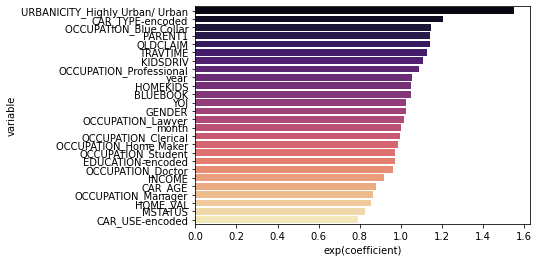

In [168]:
sns.barplot(x='exp(coefficient)', y='variable', data=result_sorted, palette="magma")

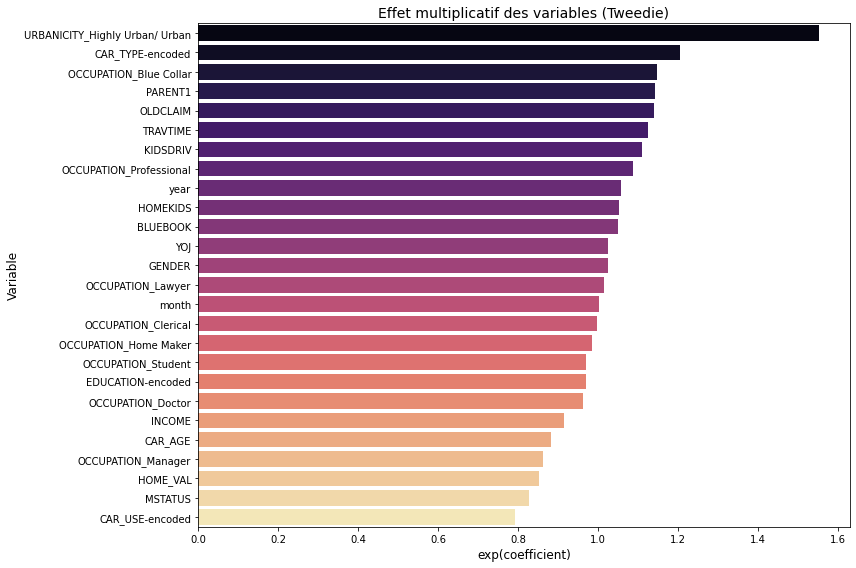

In [169]:
plt.figure(figsize=(12,8))
sns.barplot(x='exp(coefficient)', y='variable', data=result_sorted, palette="magma")
plt.title("Effet multiplicatif des variables (Tweedie)", fontsize=14)
plt.xlabel("exp(coefficient)", fontsize=12)
plt.ylabel("Variable", fontsize=12)
plt.tight_layout()
plt.show()

In [170]:
result_sorted = result.sort_values('coefficient', ascending=False)

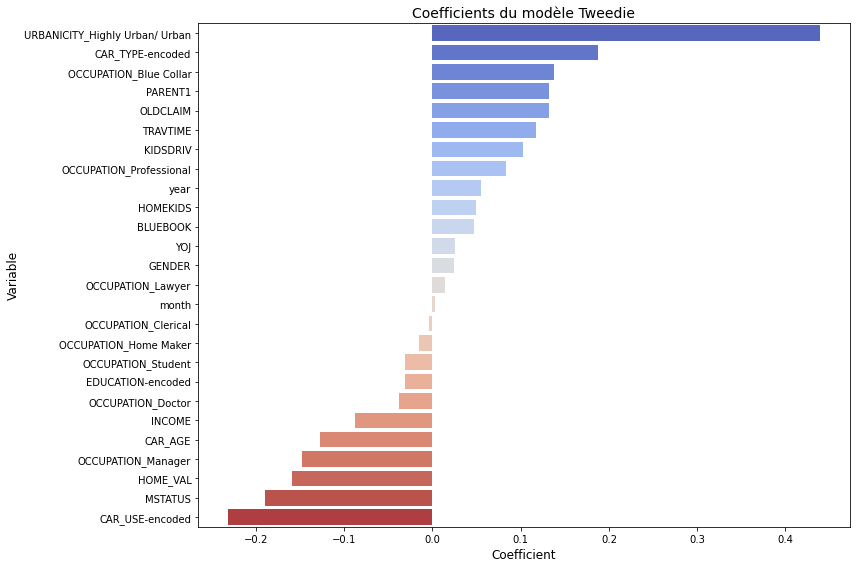

In [171]:
plt.figure(figsize=(12,8))
sns.barplot(x='coefficient', y='variable', data=result_sorted, palette="coolwarm")
plt.title("Coefficients du modèle Tweedie", fontsize=14)
plt.xlabel("Coefficient", fontsize=12)
plt.ylabel("Variable", fontsize=12)
plt.tight_layout()
plt.show()

# Les prédicions et nanalyse des prédictions

In [172]:
y_pred = model_tweedie.predict(x_train)

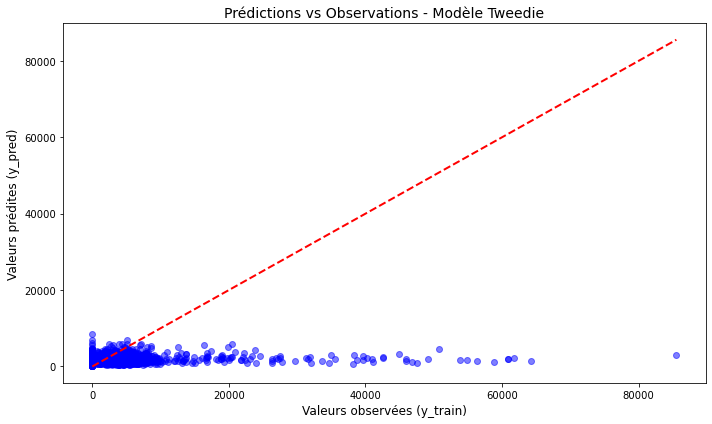

In [173]:
plt.figure(figsize=(10,6))
plt.scatter(y_train, y_pred, alpha=0.5, color="blue")
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', linewidth=2)
plt.xlabel("Valeurs observées (y_train)", fontsize=12)
plt.ylabel("Valeurs prédites (y_pred)", fontsize=12)
plt.title("Prédictions vs Observations - Modèle Tweedie", fontsize=14)
plt.tight_layout()
plt.show()

In [174]:
plt.savefig("mon_graphe.png", dpi=300, bbox_inches='tight')

<Figure size 432x288 with 0 Axes>

In [175]:
print(os.getcwd())

C:\Users\Admin


# Les résidus 

In [176]:
residuals = y_train - y_pred

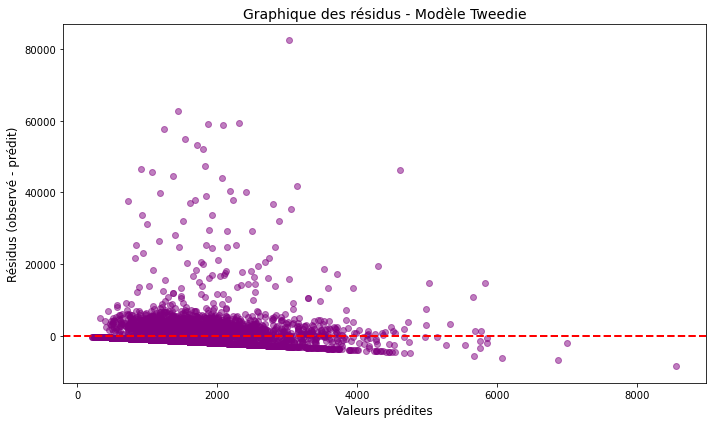

In [177]:
plt.figure(figsize=(10,6))
plt.scatter(y_pred, residuals, alpha=0.5, color="purple")
plt.axhline(0, color='red', linestyle='--', linewidth=2)

plt.xlabel("Valeurs prédites", fontsize=12)
plt.ylabel("Résidus (observé - prédit)", fontsize=12)
plt.title("Graphique des résidus - Modèle Tweedie", fontsize=14)
plt.tight_layout()
plt.show()

In [178]:
print(y_train.min(), y_train.max())
print(y_pred.min(), y_pred.max())

1e-06 85524.000001
212.5364824270663 8566.997182139572


**le modèle ne couvre pas toute l’amplitude des valeurs réelles. Il sous-estime fortement les valeurs maximales et ne prédit pas les très petites valeurs**

**modèle semble compressé : il prédit dans une plage plus étroite que la réalité**

In [179]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import TweedieRegressor

param_grid = {'power': [1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9],
              'alpha': [0, 0.1, 1, 10]}
grid = GridSearchCV(TweedieRegressor(), param_grid, cv=5, scoring='r2')
grid.fit(x_train, y_train)
print(grid.best_params_)

C:\Users\Admin\anaconda3\lib\site-packages\sklearn\linear_model\_glm\glm.py:285: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res)
C:\Users\Admin\anaconda3\lib\site-packages\sklearn\linear_model\_glm\glm.py:285: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res)
C:\Users\Admin\anaconda3\lib\site-packages\sklearn\linear_model\_glm\glm.py:285: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale 

{'alpha': 10, 'power': 1.1}


# PERFORMANCE DU MODEL: Calcul des métriques RMSE et MAE

on passe à l'évaluation des performances en calculant MAE et RSME 


on calcule le MAE mean absolute error sur l'échantillion "train" et sur l'échantillion "test"

pour l'échantillion train on la calcule entre y_train et les predictions faites sur les x_train "y_pred" car y_pred=model.predict(x_train)

In [180]:
mae_train=mean_absolute_error(y_train, y_pred)

In [181]:
print("MAE(train):",mae_train)

MAE(train): 1931.9691202069273


pour l'échantillion test on la calcule entre y_test et les predictions faites sur les x_test "y_pred_test" car y_pred_test=model.predict(x_test) qu'on va calculer d'abord

In [182]:
y_pred_test=model_tweedie.predict(x_test)

In [183]:
mae_test=mean_absolute_error(y_test, y_pred_test)

In [184]:
print("MAE(test):",mae_test)

MAE(test): 1942.521083211466


> on voit que MAE (train) est proche de MAE(test) Cela montre que le modèle ne fait pas de surapprentissage. Il généralise bien, car l’erreur sur les données qu’il n’a pas vues est presque identique à celle sur les données d’entraînement.

>La différence (1931 vs 1942) est très faible, ce qui indique une stabilité du modèle.

> on passe à une autre métrique qui est RMSE car MAE seul ne distingue pas entre les petites erreurs fréquentes et les grosses ereurs rareset RMSE pénalis d'avantage les grosses errurs et est complémentaire à MAE.

In [185]:
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred))
print("RMSE (train):", rmse_train)

RMSE (train): 4301.770343211824


In [186]:
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
print("RMSE (test):", rmse_test)

RMSE (test): 4383.243722303781


> RMSE train et RMSE test sont très proches → pas de surapprentissage, ton modèle ne s’effondre pas sur des données nouvelles.

> La valeur du RMSE est plus élevée que le MAE (1931 vs 4300), ce qui est normal car le RMSE pénalise davantage les grosses erreurs. Cela indique qu’il existe quelques prédictions avec des écarts importants.

> MAE ≈ 1931 et RMSE ≈ 4300 → cela montre que la majorité des erreurs sont raisonnables, mais qu’il existe quelques écarts importants sur des grandes valeurs.

> Ton modèle Tweedie est globalement stable (train ≈ test), mais il est moins performant sur les extrêmes ce qui est bien représenté sur mon graphe des prédictions VS Observations.

# on passe au calcule de la deviance du model tweedie

In [187]:
deviance_train=mean_tweedie_deviance(y_train,y_pred, power=1.5)

In [188]:

deviance_test=mean_tweedie_deviance(y_test,y_pred_test, power=1.5)

In [189]:
print("DEVIANCE(train):", deviance_train)

DEVIANCE(train): 143.22992458399315


In [190]:
print("DEVIANCE(test):", deviance_test)

DEVIANCE(test): 146.59136370051644


les résultats de la deviance montrent que le modèle colle bien aux données et qu'il ne fait pas de surapprentissage

on passe à "COURBES DE CALIBRATION"

Courbe de calibration : on regroupe les prédictions en intervalles (bins), puis on compare la moyenne prédite à la moyenne observée dans chaque bin. On trace ces points reliés par une courbe. Cela donne une vision plus agrégée et permet de voir si le modèle est bien calibré en moyenne.

In [191]:
df = pd.DataFrame({"y_true": y_test, "y_pred": y_pred_test})

In [192]:
df["bin"] = pd.qcut(df["y_pred"], q=10, duplicates="drop")

In [193]:
calibration = df.groupby("bin").agg(
    mean_pred=("y_pred", "mean"),
    mean_true=("y_true", "mean")
).reset_index()

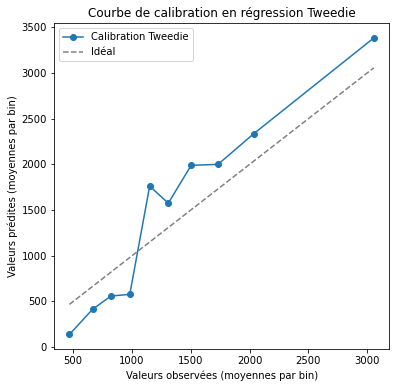

In [194]:
plt.figure(figsize=(6,6))
plt.plot(calibration["mean_pred"], calibration["mean_true"], marker="o", label="Calibration Tweedie")
plt.plot([calibration["mean_pred"].min(), calibration["mean_pred"].max()],
         [calibration["mean_pred"].min(), calibration["mean_pred"].max()],
         linestyle="--", color="gray", label="Idéal")
plt.xlabel("Valeurs observées (moyennes par bin)")
plt.ylabel("Valeurs prédites (moyennes par bin)")
plt.title("Courbe de calibration en régression Tweedie")
plt.legend()
plt.show()

on voit que mon modèle sous estime BEACOUP les valeurs jusqu'à 1000 puis il surestime mais des erreurs plus petites 

# 5 METHODE LIGHTGBM

In [195]:
categorical_features=["PARENT1","MSTATUS","GENDER","EDUCATION-encoded","CAR_TYPE-encoded","CAR_USE-encoded"]

In [196]:
modelLGB=lgb.LGBMRegressor()

## 5/1 entrainement du modèle lightGBM ##

In [197]:
modelLGB.fit(x_train,y_train, categorical_feature=categorical_features)

C:\Users\Admin\anaconda3\lib\site-packages\lightgbm\basic.py:2065: UserWarning: Using categorical_feature in Dataset.
  _log_warning('Using categorical_feature in Dataset.')


LGBMRegressor()

## 5/2 PREDICTION SUR x_test ##

In [198]:
y_pred=modelLGB.predict(x_test)

## 5/3 EVALUATION DU MODELE ##

- calcule RMSE MAE et R^2

In [203]:
rmse=root_mean_squared_error(y_test,y_pred)

In [204]:
mae=mean_absolute_error(y_test,y_pred)

In [205]:
print("RMSE:",rmse)
print("MAE:",mae)

RMSE: 4394.692927951714
MAE: 1920.8647977582948


c'est des valeurs plus élevées que la moyenne des sinistres ce qui indique que notre modèle ne capture pas bien la distribution des montants des sinistres et que le modèle n'est pas encore trés performant 

In [206]:
r2=r2_score(y_test,y_pred)

In [207]:
print("R^2:",r2)

R^2: 0.03402277307790036


> pour palier à ce problème et rendre le modèle plus performant on va calculer le log(y) au lieu de montant de sinistre pour réduire l'impact des gros sinistres sur le RMSE 

> entrainer lgb sur log(y)

> prédire log(y) puis transformer mais le résultat ne s'est pas amélioré donc je passe à ue autre méthode qui est OPTIMISATION DES HYPERPARAMETRES de lightGBM

In [208]:
modellog = lgb.LGBMRegressor(
    num_leaves=31,    
    max_depth=-1,        
    learning_rate=0.05,  
    n_estimators=500    
)

modellog.fit(x_train, y_train)

LGBMRegressor(learning_rate=0.05, n_estimators=500)

In [209]:
y_pred=modellog.predict(x_test)

In [210]:
rmse=root_mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [211]:
print("RMSE:",rmse)
print("MAE:",mae)
print("R^2:",r2)

RMSE: 4438.9169827239
MAE: 2024.6744364344634
R^2: 0.014483581343746721


In [212]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

In [213]:
def rmse(y_true, y_pred):
    return np.sqrt(root_mean_squared_error(y_test, y_pred))

In [214]:
rmse_scorer = make_scorer(rmse, greater_is_better=False)

In [215]:
param_grid = {
    'num_leaves': [15, 31, 63],
    'max_depth': [5, 10, -1],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [200, 500, 1000],
    'min_data_in_leaf': [20, 50, 100],
    'feature_fraction': [0.6, 0.8, 1.0],
    'bagging_fraction': [0.6, 0.8, 1.0]
}

# GridSearchCV
grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring=rmse_scorer,
    cv=3,              # validation croisée à 3 plis
    verbose=2,
    n_jobs=-1          # utilise tous les cœurs disponibles
)

grid.fit(x_train, y_train)

print("Meilleurs paramètres :", grid.best_params_)
print("Meilleur score RMSE :", -grid.best_score_)

NameError: name 'model' is not defined

**la méthode des hyperparamètres non plus n'a pas fonctionné on passe à la segmentation**

# 6 LA SEGMENTATION #

## 6/1 Definir les segments ##

In [217]:
mask_small=y<40000
mask_large=y>=40000
x_small,y_small=x[mask_small],y[mask_small]
x_large,y_large=x[mask_large],y[mask_large]

> il faut faire la segmentation sur toutes les valeurs de Y et avant le split pour permettre au modèle de bien apprendre des données et aussi pour nr pas prendre le risque de tomber sur des segments vides

## 6/2 split ## 

**split séparé pour chaque segment** 

In [218]:
x_train_small, x_test_small, y_train_small, y_test_small = train_test_split(
    x_small, y_small, test_size=0.2, random_state=42)

In [219]:
x_train_large, x_test_large, y_train_large, y_test_large = train_test_split(
    x_large, y_large, test_size=0.2, random_state=42)

## 6/3 ENTRAINER lightGBM sur les deux sgments ##

In [220]:
modelLGB_small=lgb.LGBMRegressor()
modelLGB_large=lgb.LGBMRegressor()
modelLGB_small.fit(x_train_small,y_train_small)
modelLGB_large.fit(x_train_large,y_train_large)

LGBMRegressor()

**maintenant on fait les prédictions LGBMR pour chaque segment**

In [221]:
y_pred_small=modelLGB_small.predict(x_test_small)
y_pred_large=modelLGB_large.predict(x_test_large)

In [222]:
mask_small=y<40000
mask_large=y>=40000
x_small,y_small=x[mask_small],y[mask_small]
x_large,y_large=x[mask_large],y[mask_large]

**on calcule RMSE et MAE pour chaque segment**

- MSE et MAE pour les petits sinistres (< 4000)

In [223]:
rmse_small = np.sqrt(root_mean_squared_error(y_test_small, y_pred_small))
mae_small=mean_absolute_error(y_test_small, y_pred_small)

- RMSE et MAE pour les gros sinistres (>= 4000)

In [224]:
rmse_large = np.sqrt(root_mean_squared_error(y_test_large, y_pred_large))
mae_large = mean_absolute_error(y_test_large, y_pred_large)

In [225]:
print("Petits sinistres (<4000) - RMSE:", rmse_small, " MAE:", mae_small)
print("Gros sinistres (>=4000) - RMSE:", rmse_large, " MAE:", mae_large)

Petits sinistres (<4000) - RMSE: 54.06380902859931  MAE: 1555.842977629071
Gros sinistres (>=4000) - RMSE: 121.34942505509993  MAE: 13679.0099994


In [226]:
mean_small = y_test_small.mean()
mean_large = y_test_large.mean()

print("Moyenne petits sinistres (<4000):", mean_small)
print("Moyenne gros sinistres (>=4000):", mean_large)

print("MAE petits sinistres:", mae_small, " -> Comparé à moyenne:", mean_small)
print("MAE gros sinistres:", mae_large, " -> Comparé à moyenne:", mean_large)

Moyenne petits sinistres (<4000): 1237.045902639351
Moyenne gros sinistres (>=4000): 50179.200001
MAE petits sinistres: 1555.842977629071  -> Comparé à moyenne: 1237.045902639351
MAE gros sinistres: 13679.0099994  -> Comparé à moyenne: 50179.200001


#--- on constate que la méthode lightGBM est plus performante pour les sinistres > 4000 car MAE < mean il représente 27%

## 6/4 ENTRAINER LA METHODE TWEEDIE SUR LES DEUX SEGMENTS ##

- Definir les segments sur train et test et faire split

In [227]:
mask_small= (y>=1000) & (y<4000)
mask_large=y>=4000
x_small,y_small=x[mask_small],y[mask_small]
x_large,y_large=x[mask_large],y[mask_large]

In [228]:
x_train_small, x_test_small, y_train_small, y_test_small = train_test_split(
    x_small, y_small, test_size=0.2, random_state=42)

In [230]:
x_train_large, x_test_large, y_train_large, y_test_large = train_test_split(
    x_large, y_large, test_size=0.2, random_state=42)

**il faut aussi standariser les valeurs avant l'entrainement**

In [231]:
scaler_small = StandardScaler()
x_train_small_scaled = scaler_small.fit_transform(x_train_small)
x_test_small_scaled = scaler_small.transform(x_test_small)
scaler_large = StandardScaler()
x_train_large_scaled = scaler_large.fit_transform(x_train_large)
x_test_large_scaled = scaler_large.transform(x_test_large)

In [232]:

model_small = TweedieRegressor(power=1.3, alpha=0.3, max_iter=300)
model_small.fit(x_train_small_scaled, y_train_small)
model_large = TweedieRegressor(power=1.3, alpha=10, max_iter=10000)
model_large.fit(x_train_large_scaled, y_train_large)

TweedieRegressor(alpha=10, max_iter=10000, power=1.3)

In [233]:
y_pred_small=model_small.predict(x_test_small_scaled)
y_pred_large=model_large.predict(x_test_large_scaled)

**calcul de RMSE et MAE pour chaque segment**

- RMSE et MAE pour les petits sinistres (< 4000)

In [234]:
rmse_small = root_mean_squared_error(y_test_small, y_pred_small)
print("RMSE segment small:", rmse_small)

RMSE segment small: 881.5852779601474


In [235]:
mae_small = mean_absolute_error(y_test_small, y_pred_small)
print("MAE segment small:", mae_small)

MAE segment small: 768.0808456403328


- RMSE et MAE pour les gros sinistres (>= 4000)

In [236]:
rmse_large = root_mean_squared_error(y_test_large, y_pred_large)
print("RMSE segment large:", rmse_large)

RMSE segment large: 8937.220726000225


In [237]:
mae_large = mean_absolute_error(y_test_large, y_pred_large)
print("MAE segment large:", mae_large)

MAE segment large: 4783.98996220535


In [238]:

mean_large = y_test_large.mean()
mean_small = y_test_small.mean()
print("Moyenne petits sinistres (<10000):", mean_small)
print("Moyenne gros sinistres (>=10000):", mean_large)

print("MAE petits sinistres:", mae_small, " -> Comparé à moyenne:", mean_small)
print("MAE gros sinistres:", mae_large, " -> Comparé à moyenne:", mean_large)

Moyenne petits sinistres (<10000): 2704.0903964802305
Moyenne gros sinistres (>=10000): 8348.511628906983
MAE petits sinistres: 768.0808456403328  -> Comparé à moyenne: 2704.0903964802305
MAE gros sinistres: 4783.98996220535  -> Comparé à moyenne: 8348.511628906983


In [239]:
mean = y_test.mean()
print("MAE:", mae)

MAE: 2024.6744364344634


# on essaye la distribution GAMMA 

In [240]:
from sklearn.linear_model import GammaRegressor

In [241]:
mask_small=y<1000
x_small,y_small=x[mask_small],y[mask_small]

In [242]:
x_train_small, x_test_small, y_train_small, y_test_small = train_test_split(
    x_small, y_small, test_size=0.2, random_state=42)

In [243]:
scaler_small = StandardScaler()
x_train_small_scaled = scaler_small.fit_transform(x_train_small)
x_test_small_scaled = scaler_small.transform(x_test_small)

In [244]:
model_gamma = GammaRegressor(alpha=0.5, max_iter=300)
model_gamma.fit(x_train_small_scaled, y_train_small)

GammaRegressor(alpha=0.5, max_iter=300)

In [245]:
y_pred_gamma = model_gamma.predict(x_test_small_scaled)

In [246]:
mae_gamma = mean_absolute_error(y_test_small, y_pred_gamma)
rmse_gamma = root_mean_squared_error(y_test_small, y_pred_gamma)

print("MAE Gamma petits sinistres:", mae_gamma)
print("RMSE Gamma petits sinistres:", rmse_gamma)

MAE Gamma petits sinistres: 22.54802626889504
RMSE Gamma petits sinistres: 106.8206475487437


In [247]:
mean_small = y_test_small.mean()
print(mean_small)

15.55399573222153


In [248]:
variance_small=np.var(y_small, ddof=1)
print("Variance_small:",variance_small)

Variance_small: 9544.047502686803


> trés grande variance veut dire trés drande disersion par rapport à la moyenne cela explique pourquoi TWEEDIE n'arrive à réduire l'erreur absolue 

**calcul de l'ecart-type**

In [249]:
std_small = np.std(y_small, ddof=1)
print("Écart-type petits sinistres:", std_small)

Écart-type petits sinistres: 97.69364105553034


> donc mon coefficient de variation est ecart-type sur la moyenne me donne 2,07 cela veut dire que les petits sinistres sont trés hétérogènes car la dispersion est deux foi plu grande que la moyenne

In [251]:
y_train_small_log = np.log1p(y_train_small)
y_test_small_log = np.log1p(y_test_small)

# --- Modèle Tweedie sur cible transformée ---
model_tweedie_log = TweedieRegressor(power=1.2, alpha=0.1, max_iter=300)
model_tweedie_log.fit(x_train_small_scaled, y_train_small_log)

# --- Prédictions et retour à l’échelle originale ---
y_pred_log = np.expm1(model_tweedie_log.predict(x_test_small_scaled))

# --- Évaluation ---
mae_log = mean_absolute_error(y_test_small, y_pred_log)
print("MAE Tweedie avec transformation log:", mae_log)
print("Moyenne petits sinistres:", y_small.mean())
print("Rapport MAE/moyenne:", mae_log / y_small.mean())

MAE Tweedie avec transformation log: 15.652340669003104
Moyenne petits sinistres: 12.626077260762738
Rapport MAE/moyenne: 1.239683580714724


 **Même après transformation log, Tweedie ne parvient pas à prédire correctement les petits sinistres : l’erreur absolue moyenne reste proportionnellement trop élevée.**

# 7 Regression Logistique #

**pour prédire si un sinistre fera partie des grands ou petits sinsitres afin de coisir quelle méthode choisir**


In [291]:
 #--- utiliser uniquement les sinistres dont les montants sont >1000 car <1000 sont ignorés (on peut simplement utiliser la mayenne)
claimsauto_filtred=claimsauto_encoded[claimsauto_encoded["CLM_AMT"]>=1000].copy()
#--- créer la varible binaire--- 
claimsauto_filtred["target"]=(claimsauto_filtred["CLM_AMT"]>=4000).astype(int)
x = claimsauto_filtred.drop(columns=["CLM_AMT", "target"])
y_bin = claimsauto_filtred["target"]
#--- split train/test
x_train,x_test,y_train_bin,y_test_bin=train_test_split(x,y_bin,test_size=0.2, random_state=42)
#---entrainement de logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(x_train, y_train_bin)

C:\Users\Admin\anaconda3\lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [292]:
 #---Entraînement Tweedie sur X_train
from sklearn.linear_model import TweedieRegressor
model_tweedie = TweedieRegressor(power=1.5, alpha=0.3, max_iter=300)
model_tweedie.fit(x_train, claimsauto_filtred.loc[x_train.index, "CLM_AMT"])

C:\Users\Admin\anaconda3\lib\site-packages\sklearn\linear_model\_linear_loss.py:294: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights


TweedieRegressor(alpha=0.3, max_iter=300, power=1.5)

# segmentation par regression logistique et application du modèle adapté ( moyenne, tweedie ou lightGBM) #

In [256]:
mean_small_claims = claimsauto_encoded.loc[claimsauto_encoded["CLM_AMT"] < 1000, "CLM_AMT"].mean()

In [293]:
def predict_claim(new_client, model_tweedie, modelLGB, log_reg, threshold=0.6):
    """
    new_client : DataFrame avec une seule ligne (features encodées)
    tweedie_model : modèle Tweedie entraîné sur 1000–4000
    modelLGB : modèle LightGBM entraîné sur ≥4000
    log_reg : modèle logistique entraîné pour classifier grand/petit sinistre
    threshold : seuil de probabilité pour classer grand/petit sinistre
    """
    # Sécuriser les colonnes : garder uniquement celles utilisées pour l'entraînement
    new_client = new_client[x.columns]

    # Vérifier si le montant réel est <1000 (cas spécial)
    if "CLM_AMT" in new_client.columns and new_client["CLM_AMT"].values[0] < 1000:
        prediction = mean_small_claims
        model_used = "Moyenne (très petit sinistre)"
        proba = None
    else:
        # Probabilité grand sinistre
        proba = log_reg.predict_proba(new_client)[:, 1][0]
        
        if proba >= threshold:
            prediction = modelLGB.predict(new_client)[0]
            model_used = "LightGBM (grand sinistre)"
        else:
            prediction = model_tweedie.predict(new_client)[0]
            model_used = "Tweedie (petit sinistre)"
    
    return {
        "Probabilité_grand_sinistre": proba,
        "Montant_prédit": prediction,
        "Modèle_utilisé": model_used}

## Exemple d'utilisation ##

In [294]:
#---on suppose qu'on prend comme nouveau client la ligne 11 du test
new_client=x_test.iloc[[10]]
Result=predict_claim(new_client, model_tweedie, modelLGB, log_reg)
print(Result)

{'Probabilité_grand_sinistre': 0.48951018845771976, 'Montant_prédit': 5890.57608695652, 'Modèle_utilisé': 'Tweedie (petit sinistre)'}


In [295]:
print("Client 9 :", model_tweedie.predict(x_test.iloc[[9]])[0])
print("Client 10 :", model_tweedie.predict(x_test.iloc[[10]])[0])

Client 9 : 5890.57608695652
Client 10 : 5890.57608695652


**Le modèle Tweedie produisait des prédictions identiques pour plusieurs clients, ce qui a révélé un manque de discrimination.** 
**À partir de ce constat, nous avons décidé de filtrer les variables peu discriminantes et de ré‑entraîner le modèle dans la partie B du notebook.**

# PARTIE B #

## B/1 calcul de l'importance des variables explicatives ##

In [268]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor()
rf.fit(x_train, claimsauto_filtred.loc[x_train.index, "CLM_AMT"])
importances = pd.Series(rf.feature_importances_, index=x.columns)
print(importances.sort_values(ascending=False).head(26))

BLUEBOOK                          0.160594
INCOME                            0.108641
year                              0.106006
TRAVTIME                          0.098805
OLDCLAIM                          0.070923
month                             0.069146
HOME_VAL                          0.067535
YOJ                               0.056972
CAR_AGE                           0.053653
CAR_TYPE-encoded                  0.040966
EDUCATION-encoded                 0.025630
HOMEKIDS                          0.018709
OCCUPATION_Professional           0.017020
OCCUPATION_Blue Collar            0.013936
KIDSDRIV                          0.013365
URBANICITY_Highly Urban/ Urban    0.012876
MSTATUS                           0.010877
OCCUPATION_Home Maker             0.009936
PARENT1                           0.009519
CAR_USE-encoded                   0.008996
OCCUPATION_Student                0.008681
GENDER                            0.008654
OCCUPATION_Clerical               0.004474
OCCUPATION_

## Résultats ##

> Les variables dominantes sont BLUEBOOK (valeur du véhicule), year, TRAVTIME, INCOME et HOME_VAL. Elles concentrent à elles seules plus de 50 % de l’importance totale.

> Les variables comme month, OLDCLAIM, YOJ et CAR_AGE ont une importance intermédiaire.

> Les variables catégorielles encodées (CAR_TYPE, EDUCATION, certaines occupations) apportent un signal mais beaucoup plus faible.

> Enfin, des variables comme OCCUPATION_Doctor ou OCCUPATION_Manager sont quasi négligeables (importance proche de zéro).

> L’analyse des importances via RandomForest montre que les variables liées à la valeur du véhicule (BLUEBOOK), au revenu et au temps de trajet sont les plus déterminantes pour prédire le montant des sinistres. À l’inverse, certaines variables catégorielles (occupation, statut marital, genre) ont un poids très faible, ce qui confirme qu’elles sont peu discriminantes et peuvent être candidates à l’exclusion du pipeline.

In [269]:
def check_features_discriminance(X):
    summary = []
    for col in X.columns:
        unique_vals = X[col].nunique()
        variance = X[col].var()
        summary.append({
            "Variable": col,
            "Nb_valeurs_uniques": unique_vals,
            "Variance": variance
        })
    return pd.DataFrame(summary).sort_values(by="Nb_valeurs_uniques", ascending=False)

# Exemple d’utilisation
feature_summary = check_features_discriminance(x)
print(feature_summary.head(26))

                          Variable  Nb_valeurs_uniques      Variance
3                           INCOME                1652  1.463182e+09
9                         BLUEBOOK                1289  6.111360e+07
10                        OLDCLAIM                1127  1.023883e+08
5                         HOME_VAL                1110  1.265400e+10
8                         TRAVTIME                  81  2.328642e+02
12                            year                  57  9.512013e+01
11                         CAR_AGE                  26  2.753830e+01
2                              YOJ                  20  2.084516e+01
13                           month                  12  1.205230e+01
15                CAR_TYPE-encoded                   6  2.211228e+00
1                         HOMEKIDS                   6  1.422283e+00
14               EDUCATION-encoded                   5  1.100889e+00
0                         KIDSDRIV                   4  3.696889e-01
7                           GENDER

## Analyse ##

**on remarque que les variables avec les variances les plus faibles sont:**
> OCCUPATION_Doctor → 0.0151

> URBANICITY_Highly Urban/ Urban → 0.0504

> OCCUPATION_Manager → 0.0576

> OCCUPATION_Lawyer → 0.0700

> OCCUPATION_Home Maker → 0.0781

> PARENT1 → 0.1750

> OCCUPATION_Clerical → 0.1560 

En comparant avec les importances du RandomForest, on remarque une cohérence : plusieurs d’entre elles (Doctor, Manager, Lawyer, Clerical) sont aussi très faibles en importance.

Cela confirme qu’elles sont doublement faibles (faible variance + faible importance), donc candidates à l’exclusion de mon pipeline Tweedie/LightGBM.

## B/2 Suppression des variables peu discriminantes ##

In [273]:
vars_to_remove=["CAR_USE-encoded",
                "OCCUPATION_Student",
                "GENDER",
                "OCCUPATION_Clerical",
                "OCCUPATION_Lawyer",
                "OCCUPATION_Manager",
                "OCCUPATION_Doctor"]
claimsauto_encoded_reduite= claimsauto_encoded.drop(columns=vars_to_remove,errors="ignore")

In [274]:
claimsauto_encoded_reduite

,KIDSDRIV,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,TRAVTIME,BLUEBOOK,OLDCLAIM,CLM_AMT,CAR_AGE,year,month,EDUCATION-encoded,CAR_TYPE-encoded,OCCUPATION_Blue Collar,OCCUPATION_Home Maker,OCCUPATION_Professional,URBANICITY_Highly Urban/ Urban
0,0,2,13,26763,1,141019,0,49,11500,0,0,11,1955,2,3,3,0,0,0,1
1,0,0,9,156060,0,381438,1,29,25230,8207,0,9,1961,10,1,1,1,0,0,1
2,0,1,11,1965,1,0,0,21,20630,0,0,11,1959,11,4,0,0,1,0,1
3,0,1,10,62361,0,185738,1,32,11540,3481,0,6,1961,10,1,3,0,1,0,1
4,0,1,10,34192,1,0,0,22,13670,0,0,7,1966,10,2,3,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7642,0,0,11,67813,0,249997,1,51,21190,0,0,6,1938,8,1,4,0,0,1,0
7643,0,2,11,13490,0,95447,1,5,5850,31401,4578,1,1968,12,2,2,0,0,0,1
7644,0,1,11,44955,0,161808,1,30,18790,0,3128,7,1957,3,1,0,0,0,1,1
7645,0,0,13,36835,0,167142,1,20,17360,32434,0,10,1951,6,2,0,1,0,0,1


## B/3 Réentrainement des deux modèls ##

In [304]:
import pandas as pd
from sklearn.linear_model import TweedieRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# 1. Séparation features / cible
x = claimsauto_encoded.drop(columns=["CLM_AMT"])
y = claimsauto_encoded["CLM_AMT"]
# 2. Split train/test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
# 3. Nettoyage des variables faibles
vars_to_remove=["CAR_USE-encoded",
                "OCCUPATION_Student",
                "GENDER",
                "OCCUPATION_Clerical",
                "OCCUPATION_Lawyer",
                "OCCUPATION_Manager",
                "OCCUPATION_Doctor"]
claimsauto_encoded_reduite= claimsauto_encoded.drop(columns=vars_to_remove,errors="ignore")
# 4. Re-séparation features / cible sur la base réduite
x_reduit = claimsauto_encoded_reduite.drop(columns=["CLM_AMT"])
y_reduit = claimsauto_encoded_reduite["CLM_AMT"]

x_train_red, x_test_red, y_train_red, y_test_red = train_test_split(x_reduit, y_reduit, test_size=0.2, random_state=100)
# 5. Entraînement Tweedie
ontinuous_vars = [
    col for col in x_train_red.select_dtypes(include=["int64","float64"]).columns
    if x_train_red[col].nunique() > 2
]
scaler = StandardScaler()
x_train_red[continuous_vars] = scaler.fit_transform(x_train_red[continuous_vars])
x_test_red[continuous_vars] = scaler.transform(x_test_red[continuous_vars])
model_tweedie = TweedieRegressor(power=1.5,alpha=10,link="log", max_iter=10000)
model_tweedie.fit(x_train_red, y_train_red)
y_pred_tweedie = model_tweedie.predict(x_test_red)
mae_tweedie = mean_absolute_error(y_test_red, y_pred_tweedie)
# 6. Entraînement LightGBM
modelLGB= LGBMRegressor(random_state=1000)
modelLGB.fit(x_train_red, y_train_red)
y_pred_lgbm = modelLGB.predict(x_test_red)
mae_lgbm = mean_absolute_error(y_test_red, y_pred_lgbm)
# 6. Entraînement Llogistic Regression
 #--- utiliser uniquement les sinistres dont les montants sont >1000 car <1000 sont ignorés (on peut simplement utiliser la mayenne)
claimsauto_filtred=claimsauto_encoded_reduite[claimsauto_encoded_reduite["CLM_AMT"]>=1000].copy()
#--- créer la varible binaire--- 
claimsauto_filtred["target"]=(claimsauto_filtred["CLM_AMT"]>=4000).astype(int)
x_red = claimsauto_filtred.drop(columns=["CLM_AMT", "target"])
y_bin = claimsauto_filtred["target"]
#--- split train/test
x_train_red,x_test_red,y_train_bin,y_test_bin=train_test_split(x_red,y_bin,test_size=0.2, random_state=42)
continuous_vars = [
    col for col in x_train_red.select_dtypes(include=["int64","float64"]).columns
    if x_train_red[col].nunique() > 2
]
scaler = StandardScaler()
x_train_red[continuous_vars] = scaler.fit_transform(x_train_red[continuous_vars])
x_test_red[continuous_vars] = scaler.transform(x_test_red[continuous_vars])
#---entrainement de logistic Regression
log_reg = LogisticRegression(max_iter=10000)
log_reg.fit(x_train_red, y_train_bin)

LogisticRegression(max_iter=10000)

In [305]:
print("MAE Tweedie (après nettoyage):", mae_tweedie)
print("MAE LightGBM (après nettoyage):", mae_lgbm)

MAE Tweedie (après nettoyage): 1871.3294711450021
MAE LightGBM (après nettoyage): 1806.8620602851895


- **Remarque:**
- Les deux modèles ont gagné en performance par rapport aux versions avec toutes les variables (où MAE était plus élevé).

## B/4 segmentation par regression logistique et application du modèle adapté ( moyenne, tweedie ou lightGBM ##

In [307]:
mean_small_claims = claimsauto_encoded_reduite.loc[claimsauto_encoded_reduite["CLM_AMT"] < 1000, "CLM_AMT"].mean()

In [308]:
def predict_claim(new_client, model_tweedie, modelLGB, log_reg, threshold=0.6):
    """
    new_client : DataFrame avec une seule ligne (features encodées)
    tweedie_model : modèle Tweedie entraîné sur 1000–4000
    modelLGB : modèle LightGBM entraîné sur ≥4000
    log_reg : modèle logistique entraîné pour classifier grand/petit sinistre
    threshold : seuil de probabilité pour classer grand/petit sinistre
    """
    # Sécuriser les colonnes : garder uniquement celles utilisées pour l'entraînement
    new_client = new_client[x_red.columns]

    # Vérifier si le montant réel est <1000 (cas spécial)
    if "CLM_AMT" in new_client.columns and new_client["CLM_AMT"].values[0] < 1000:
        prediction = mean_small_claims
        model_used = "Moyenne (très petit sinistre)"
        proba = None
    else:
        # Probabilité grand sinistre
        proba = log_reg.predict_proba(new_client)[:, 1][0]
        
        if proba >= threshold:
            prediction = modelLGB.predict(new_client)[0]
            model_used = "LightGBM (grand sinistre)"
        else:
            prediction = model_tweedie.predict(new_client)[0]
            model_used = "Tweedie (petit sinistre)"
    
    return {
        "Probabilité_grand_sinistre": proba,
        "Montant_prédit": prediction,
        "Modèle_utilisé": model_used}

In [311]:
new_client=x_test_red.iloc[[4]]
Result=predict_claim(new_client, model_tweedie, modelLGB, log_reg)
print(Result)

{'Probabilité_grand_sinistre': 0.5388670373894121, 'Montant_prédit': 1297.2732203155272, 'Modèle_utilisé': 'Tweedie (petit sinistre)'}
